# Stability and uncertainty: how far an identified parameter can be trusted

> **Repository:** [PINNs-RL-PDE](https://github.com/josegarciav/PINNs-RL-PDE) · **Docs:** [Well-posedness and stability](https://josegarciav.github.io/PINNs-RL-PDE/theory/well_posedness/) · [The Bayesian view](https://josegarciav.github.io/PINNs-RL-PDE/theory/bayesian/) · [Equivalence regions](https://josegarciav.github.io/PINNs-RL-PDE/theory/equivalence_regions/) · [API: uq](https://josegarciav.github.io/PINNs-RL-PDE/api/uq/)

Notebooks 06 and 07 established how accurate an identified parameter is and what limits it. This one asks the two questions a plant would ask next: **how does the estimate move when the data or the problem are disturbed** (roadmap item 4, experiments K05–K07), and **what interval should be put on it** (item 5, experiments F06/K10, K39, K46).

| Experiment | Question | Folder |
|---|---|---|
| K05 | Response of the estimate to sensor bias, delay, noise, dropout and outliers, vs the linear prediction | `experiments/K05_data_disturbance` |
| K06 | Does the trained field respond to a perturbed problem as the equation does? | `experiments/K06_problem_disturbance` |
| K07 | How does the training residual translate into solution error? | `experiments/K07_stability_constants` |
| F06 / K10 | Are the intervals (ensemble, Laplace, Fisher, swarm) calibrated? | `experiments/F06_coverage` |
| K39 | Should the data weight come from the noise model? | `experiments/K39_likelihood_weighting` |
| K46 | Does a swarm recover the nonlinear region of equivalence? | `experiments/K46_swarm_equivalence` |

## The problem, in symbols

For the estimate $\hat\theta$ of a weighted least-squares fit to observations $y = u(\theta) + \varepsilon$, a disturbance $\delta y$ of the data moves the estimate, to first order, by

$$
\delta\theta \;\approx\; (J^\top \Sigma^{-1} J)^{-1} J^\top \Sigma^{-1}\, \delta y \;=\; F^{-1} J^\top \Sigma^{-1} \delta y ,
$$

so the Fisher information $F$ is both the covariance of random errors and the **gain** on systematic ones. K05 measures the PINN's actual shift against this prediction for disturbances a plant produces.

For the forward problem, the error estimate of the numerical-analysis bridge reads

$$
\|u - u_w\| \;\le\; C\,\big(\,\|\mathcal{N}[u_w]\| + \|\mathcal{B}u_w - g\| + \|u_w(\cdot,0) - u_0\| + \mathcal{E}_{\text{quad}}\,\big),
$$

with $C$ the stability constant of the equation. K07 measures the empirical $C = \text{error}/\text{residual}$ on an independent sample, and K06 asks whether a trained field perturbed in its data moves as the exact solution does (amplification $\|\delta u_{\text{PINN}}\| / \|\delta u_{\text{exact}}\|$).

For the interval, three candidates are compared by their **coverage** (how often a 90 % interval contains the truth over many data sets), **width** and **CRPS**: the ensemble of estimates from different initializations, the Laplace posterior $\mathcal{N}(\hat\theta, F^{-1})$ with $F$ from the surrogate's sensitivities, and the likelihood-ratio region $\{\theta : \text{misfit}(\theta) - \text{misfit}_{\min} \le \sigma^2 \chi^2_p(0.9)\}$ sampled by a particle swarm.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXP = ROOT / "experiments"
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


def load(exp):
    """The raw runs of an experiment (every seed, every cell), or None if it has not been run."""
    path = EXP / exp / "results" / "runs.json"
    if not path.exists():
        display(Markdown(f"> **{exp} has no results yet.** Run `python experiments/{exp}/run.py` first."))
        return None
    return json.loads(path.read_text())


def figure(exp, png, script="plot.py"):
    """Re-render an experiment's figure from its raw results with its own plot script, then show it."""
    if not (EXP / exp / "results").exists():
        display(Markdown(f"> **{exp} has no results yet**, so its figure cannot be rendered."))
        return
    subprocess.run([sys.executable, str(EXP / exp / script)], check=True, capture_output=True)
    display(Image(filename=str(EXP / exp / "results" / png), width=1100))


def table(header, rows):
    """A Markdown table from a header list and rows of already formatted strings."""
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def med_iqr(values):
    v = np.asarray(values, dtype=float)
    q25, q75 = np.percentile(v, [25, 75])
    return f"{np.median(v):.3f} [{q25:.3f}, {q75:.3f}]"


def readme(exp, section="Conclusion"):
    """Show one section of the experiment's README, so the notebook and the folder say the same thing."""
    text = (EXP / exp / "README.md").read_text()
    body = text.split(f"## {section}")[1].split("\n## ")[0] if f"## {section}" in text else ""
    display(Markdown(f"**{section} (from `experiments/{exp}/README.md`)**\n" + body))

## K05: response to data disturbances

**Setup.** The F01 heat problem (200 observations at noise 0.05) disturbed in five ways, each applied to the same data set and initial weights as the undisturbed run of the same seed, so every shift is paired: extra noise, a constant bias on all points or on one of four probes, a timestamp delay ($y$ attributed to $t + \tau$), random dropout or the loss of a whole probe, and outliers. The predicted shift uses the exact sensitivity $J = -\pi^2 t\,u$ and `pinnrl.analysis.linear_response`.

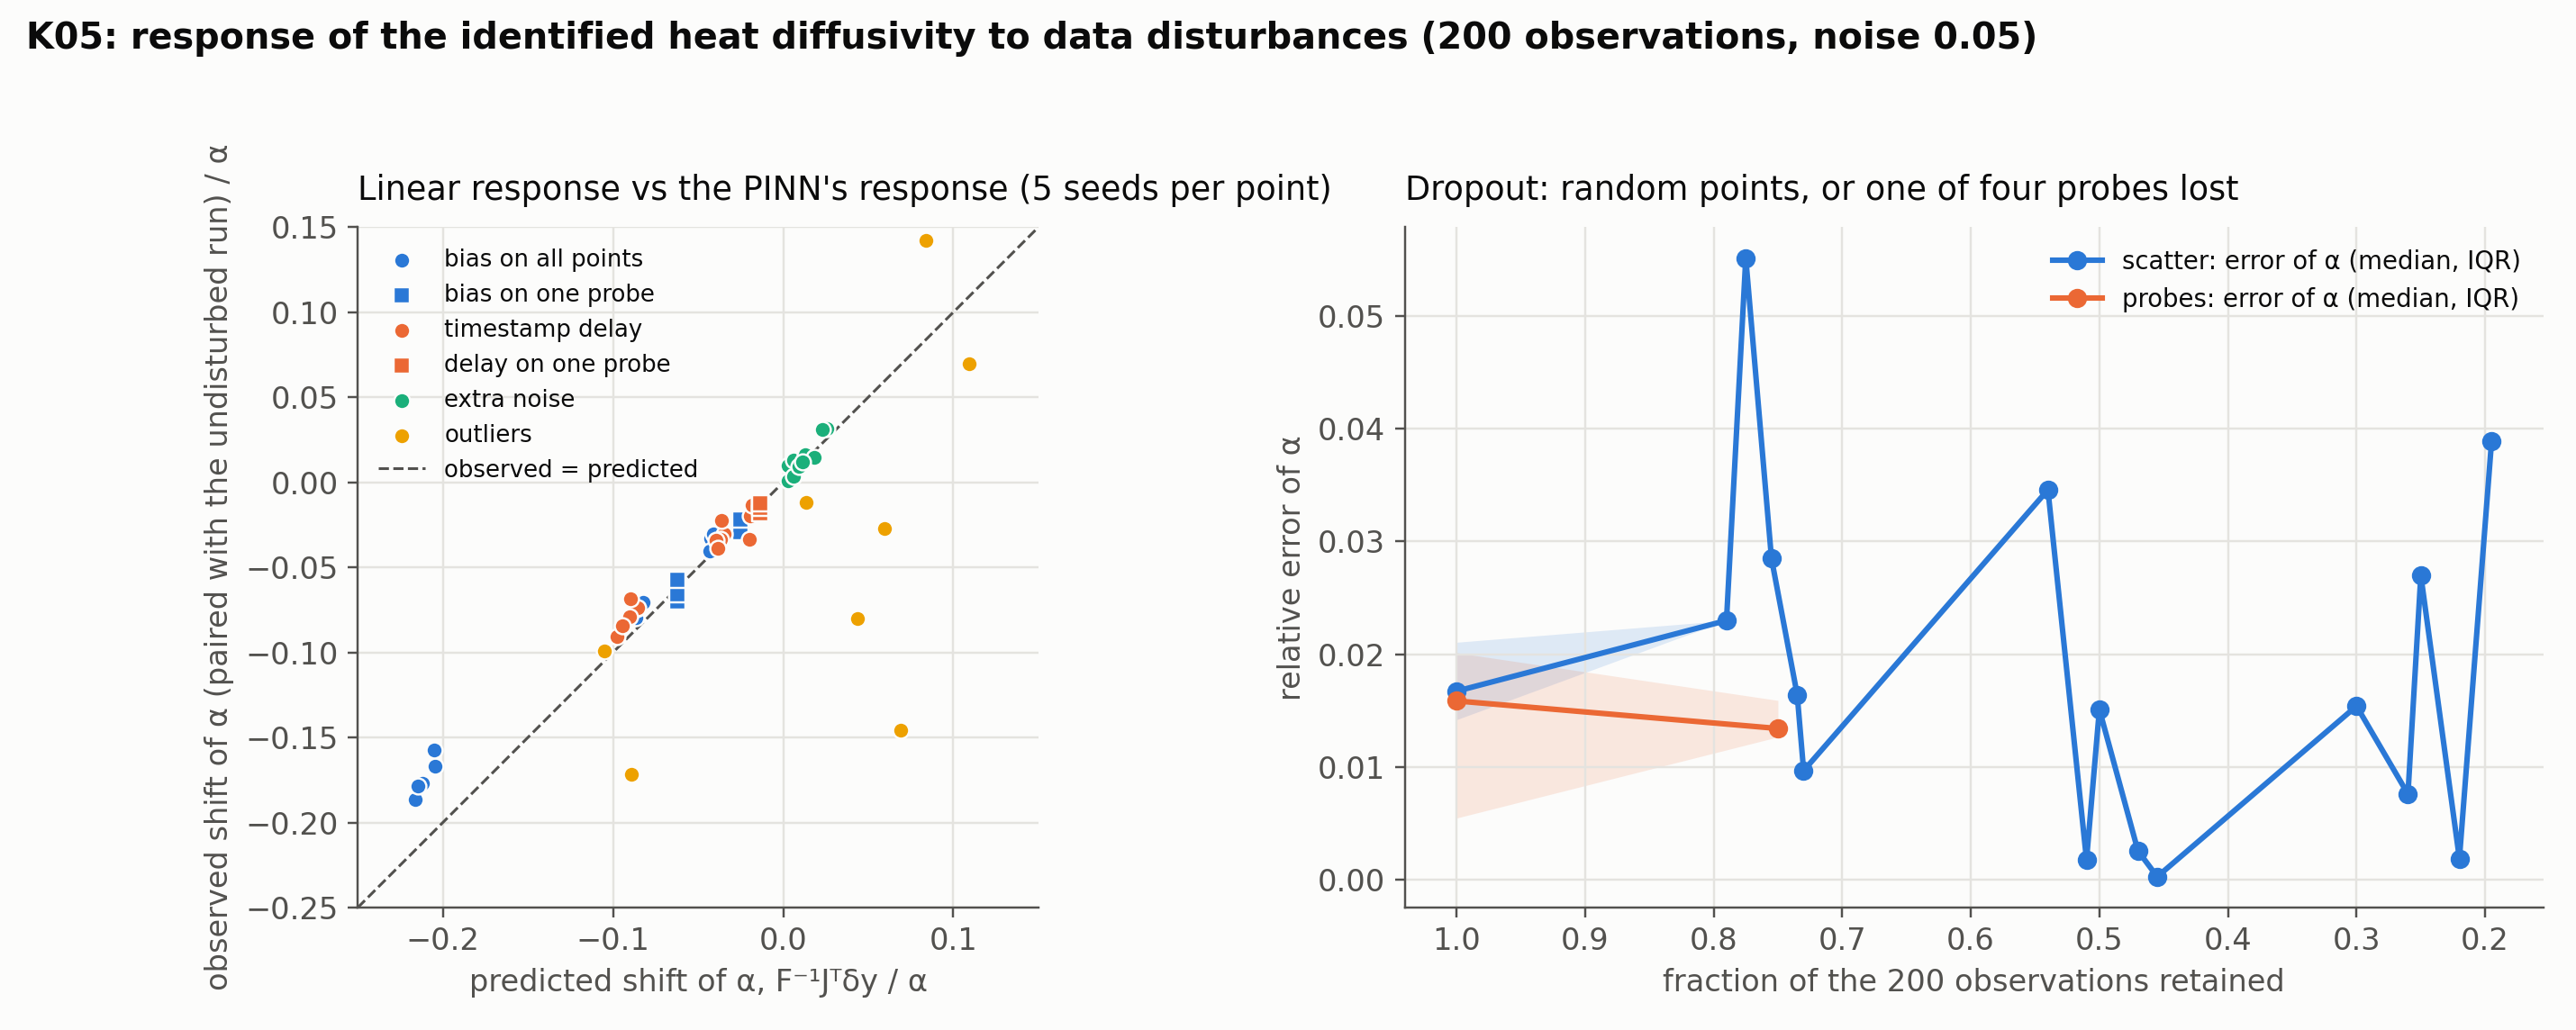

In [2]:
runs = load("K05_data_disturbance")
figure("K05_data_disturbance", "k05_data_disturbance.png")

In [3]:
base = {(r["layout"], r["seed"]): r["alpha_hat"] for r in runs if r["kind"] == "none"}
rows = []
for lay, kind, mag in sorted({(r["layout"], r["kind"], r["magnitude"]) for r in runs if r["kind"] != "none"}, key=lambda k: (k[0] != "scatter", k[1], k[2])):
    sel = [r for r in runs if (r["layout"], r["kind"], r["magnitude"]) == (lay, kind, mag)]
    shift = np.array([r["alpha_hat"] - base[(r["layout"], r["seed"])] for r in sel]) / 0.1
    pred = np.array([r["predicted_shift"] for r in sel]) / 0.1
    ok = np.all(np.isfinite(pred)) and np.abs(pred).min() > 1e-4
    rows.append([lay, kind, mag, f"{np.median(shift):+.3f}", f"{np.median(pred):+.3f}" if ok else "–", f"{np.median(shift / pred):.2f}" if ok else "–",
                 f"{np.median([r['residual_loss'] for r in sel]):.1e}"])
table(["layout", "disturbance", "size", "observed shift / α", "predicted / α", "ratio", "residual loss"], rows)
readme("K05_data_disturbance")

| layout | disturbance | size | observed shift / α | predicted / α | ratio | residual loss |
|---|---|---|---|---|---|---|
| scatter | bias | 0.01 | -0.033 | -0.042 | 0.78 | 9.1e-04 |
| scatter | bias | 0.02 | -0.074 | -0.085 | 0.87 | 1.0e-03 |
| scatter | bias | 0.05 | -0.177 | -0.212 | 0.83 | 1.5e-03 |
| scatter | delay | 0.01 | -0.016 | -0.019 | 0.94 | 9.2e-04 |
| scatter | delay | 0.02 | -0.033 | -0.037 | 0.87 | 9.9e-04 |
| scatter | delay | 0.05 | -0.079 | -0.090 | 0.88 | 1.3e-03 |
| scatter | dropout | 0.25 | +0.011 | – | – | 8.6e-04 |
| scatter | dropout | 0.5 | +0.015 | – | – | 1.0e-03 |
| scatter | dropout | 0.75 | +0.048 | – | – | 1.1e-03 |
| scatter | noise | 0.05 | +0.010 | +0.009 | 1.05 | 1.0e-03 |
| scatter | noise | 0.1 | +0.014 | +0.018 | 1.24 | 1.3e-03 |
| scatter | outliers | 0.05 | +0.070 | +0.084 | 0.64 | 1.1e-02 |
| scatter | outliers | 0.1 | -0.099 | +0.059 | 0.94 | 2.3e-02 |
| probes | bias_one | 0.02 | -0.026 | -0.025 | 1.06 | 1.1e-03 |
| probes | bias_one | 0.05 | -0.064 | -0.062 | 1.03 | 1.5e-03 |
| probes | delay_one | 0.02 | -0.013 | -0.013 | 0.99 | 1.2e-03 |
| probes | dropout_one | 1.0 | +0.003 | – | – | 9.2e-04 |

**Conclusion (from `experiments/K05_data_disturbance/README.md`)**


1. **The PINN's response to bias and delay is the linear response, to within 20 %.** Observed shifts are 0.78–1.06 of $F^{-1} J^\top \delta y$ with interquartile ranges of a few $10^{-4}$: for a given disturbance the shift is deterministic, and the Fisher machinery of K01 predicts it before any training. On the probe layout, where the disturbed points are known, the prediction is exact (1.03–1.06); on random scatter the PINN is 10–20 % less sensitive than the linear theory, which is the surrogate's smoothing of a disturbance it cannot fit exactly.
2. **A bias is the worst disturbance per unit size and a delay the most insidious.** A bias of 0.05 (the noise level) moves $\alpha$ by 18 %, far more than noise of the same size (1 %), because a bias is coherent and the noise averages out; a delay of 0.05 on a unit time scale moves it by 8 %, and the residual does not flag either (it rises by 10–70 %, within the seed-to-seed range). Both are detected only by a model of the sensor, not by the physics.
3. **Dropout costs information, not accuracy.** Losing 75 % of the points or a whole probe shifts the estimate by under 5 % and leaves the residual unchanged; the bound grows as $1/\sqrt{N}$ and the spread across seeds with it, but there is no systematic shift. For the plant this means a lost probe degrades the interval, not the estimate.
4. **Outliers break the squared-error data term, and the residual sees it.** With 5–10 % outliers the shift becomes seed-dependent (IQR ten times wider), the linear prediction is not followed (an outlier is not a small disturbance), and the residual loss rises 10–25× while the field error doubles or quadruples. A robust data loss (`loss_function: huber` or `mae`, experiment K28) is the fix; the residual jump is the detector.

**Consequences for the backlog:**
- K25–K27 (bias, missing data, timing) have their baselines; the linear response is accurate enough that their sweeps can be predicted from $J$ and verified on a few cells.
- K28 (robust losses) is the pending item: the squared-error data term has no breakdown resistance.
- The residual loss is a usable sensor-health signal for outliers but not for bias or delay; the twin needs sensor models for those.


## K06: response to a perturbed problem

**Setup.** Forward heat and wave problems perturbed in the initial amplitude, a coefficient or a boundary value by 1, 5 and 20 %, each trained from the same initial weights as the unperturbed problem; the exact perturbed solutions are known. The amplification compares the change of the trained field with the change of the exact solution on 4,000 fixed points.

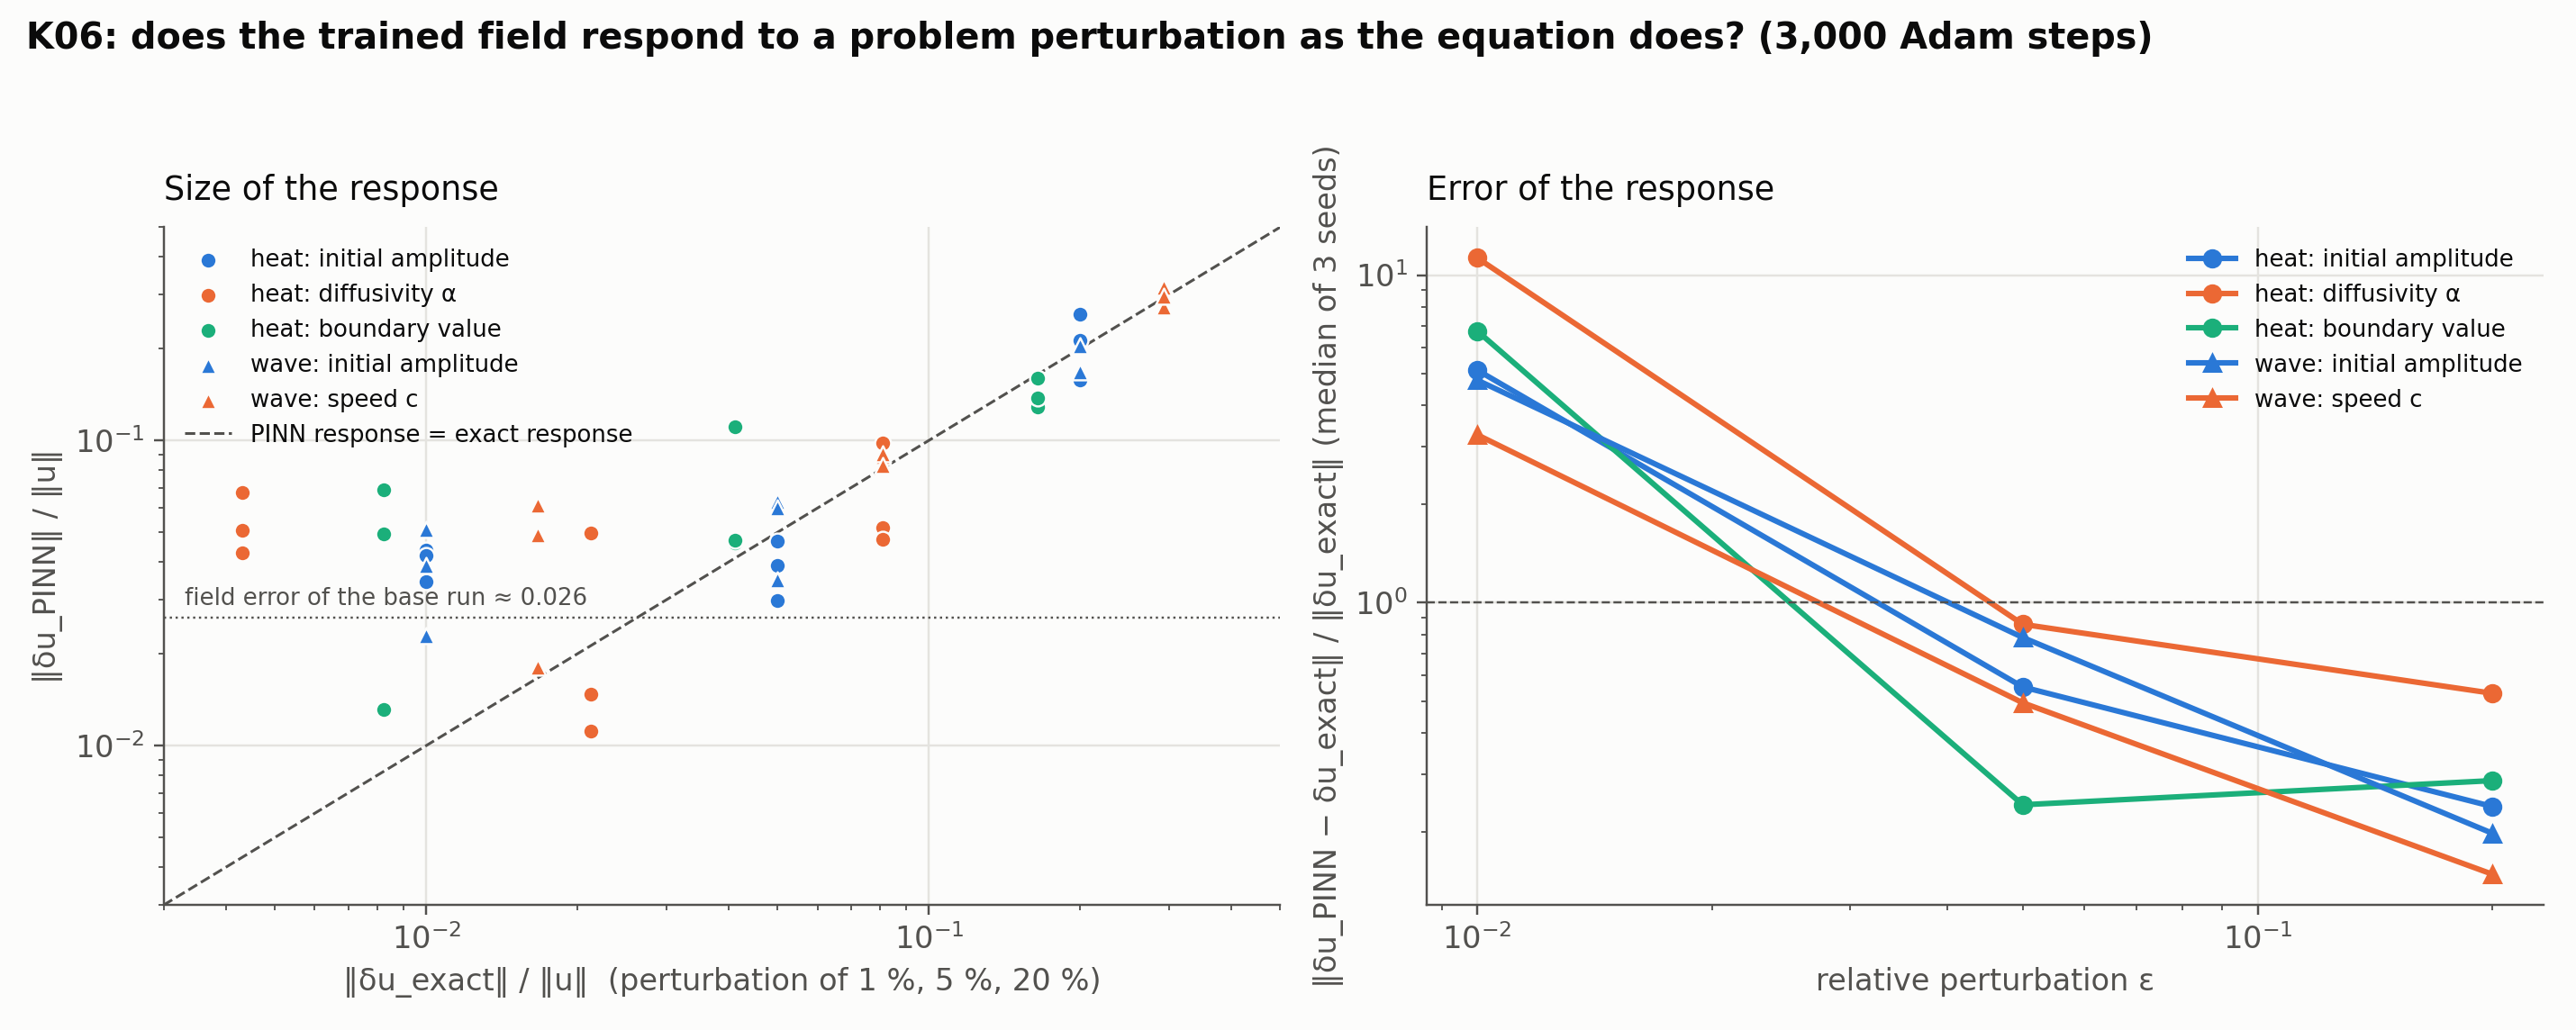

| problem | perturbation | ε | exact response | PINN response | amplification | error of the response |
|---|---|---|---|---|---|---|
| heat | ic | 0.01 | 0.010 | 0.042 | 4.33 | 5.13 |
| heat | ic | 0.05 | 0.050 | 0.039 | 0.80 | 0.55 |
| heat | ic | 0.2 | 0.200 | 0.213 | 1.10 | 0.24 |
| heat | alpha | 0.01 | 0.004 | 0.051 | 12.14 | 11.29 |
| heat | alpha | 0.05 | 0.021 | 0.015 | 0.68 | 0.86 |
| heat | alpha | 0.2 | 0.081 | 0.052 | 0.66 | 0.53 |
| heat | bc | 0.01 | 0.008 | 0.049 | 6.12 | 6.75 |
| heat | bc | 0.05 | 0.041 | 0.047 | 1.18 | 0.24 |
| heat | bc | 0.2 | 0.165 | 0.138 | 0.86 | 0.29 |
| wave | ic | 0.01 | 0.010 | 0.039 | 3.94 | 4.78 |
| wave | ic | 0.05 | 0.050 | 0.060 | 1.22 | 0.78 |
| wave | ic | 0.2 | 0.200 | 0.171 | 0.86 | 0.20 |
| wave | c | 0.01 | 0.017 | 0.049 | 2.96 | 3.25 |
| wave | c | 0.05 | 0.081 | 0.088 | 1.10 | 0.49 |
| wave | c | 0.2 | 0.293 | 0.298 | 1.02 | 0.15 |

**Conclusion (from `experiments/K06_problem_disturbance/README.md`)**


1. **Above its own error, the PINN responds as the equation does.** For perturbations whose exact response exceeds the field error of the trained network (about 3 %), the amplification is 0.7–1.2 and the response error falls from about 0.5 at ε = 0.05 to 0.15–0.3 at ε = 0.2: the trained field moves the right amount in roughly the right direction, for a change of the initial data, of the boundary data, of a diffusivity and of a wave speed. The learned solution respects the stability of the heat and wave equations to within its own accuracy.
2. **Below its own error, the response is noise.** At ε = 0.01 the exact response (0.4–1.7 %) is smaller than the training-to-training variation of the field, and the measured amplification is 3–12 with a response error of 3–11: two trainings of the same seed on problems that differ by 1 % differ by about 4 % for reasons unrelated to the perturbation. The surrogate has a **resolution**, the field error, below which it cannot be used to compute a response, and a sensitivity study on a trained PINN must check the perturbation against it.
3. **The resolution limit is the same floor as in F01–F03.** It is the surrogate's forward error again, now seen as the smallest change of the problem the surrogate can register. The implicit-function-theorem sensitivities of K01 do not suffer from it because they differentiate the trained network analytically instead of retraining; for responses to finite perturbations of the problem, retraining with a shared initialization (paired, as here) is the method, and only above the floor.

**Consequences for the backlog:**
- Response studies on trained surrogates (K31, the process twins' what-if scenarios) report the field error as the resolution and perturb above it, or use the K01 derivatives for small perturbations.
- Warm-started retraining (initializing the perturbed problem from the base network) should lower the resolution by removing the initialization noise; a follow-up cell for K06.


In [4]:
rows_k06 = json.loads((EXP / "K06_problem_disturbance" / "results" / "responses.json").read_text())
figure("K06_problem_disturbance", "k06_problem_disturbance.png")
rows = []
for p, k in [("heat", "ic"), ("heat", "alpha"), ("heat", "bc"), ("wave", "ic"), ("wave", "c")]:
    for eps in sorted({r["eps"] for r in rows_k06}):
        sel = [r for r in rows_k06 if r["problem"] == p and r["kind"] == k and r["eps"] == eps]
        rows.append([p, k, eps, f"{np.median([r['exact_response'] for r in sel]):.3f}", f"{np.median([r['pinn_response'] for r in sel]):.3f}",
                     f"{np.median([r['amplification'] for r in sel]):.2f}", f"{np.median([r['response_error'] for r in sel]):.2f}"])
table(["problem", "perturbation", "ε", "exact response", "PINN response", "amplification", "error of the response"], rows)
readme("K06_problem_disturbance")

## K07: empirical stability constants

**Setup.** Ten catalogue equations with a closed form, trained for 500 to 8,000 steps; at each budget `pinnrl.analysis.stability_ratio` evaluates the residual, the boundary and initial mismatches and the error on 8,192 fresh points. The slope of $\log(\text{error})$ against $\log(\text{residual})$ says whether the error follows the residual at all.

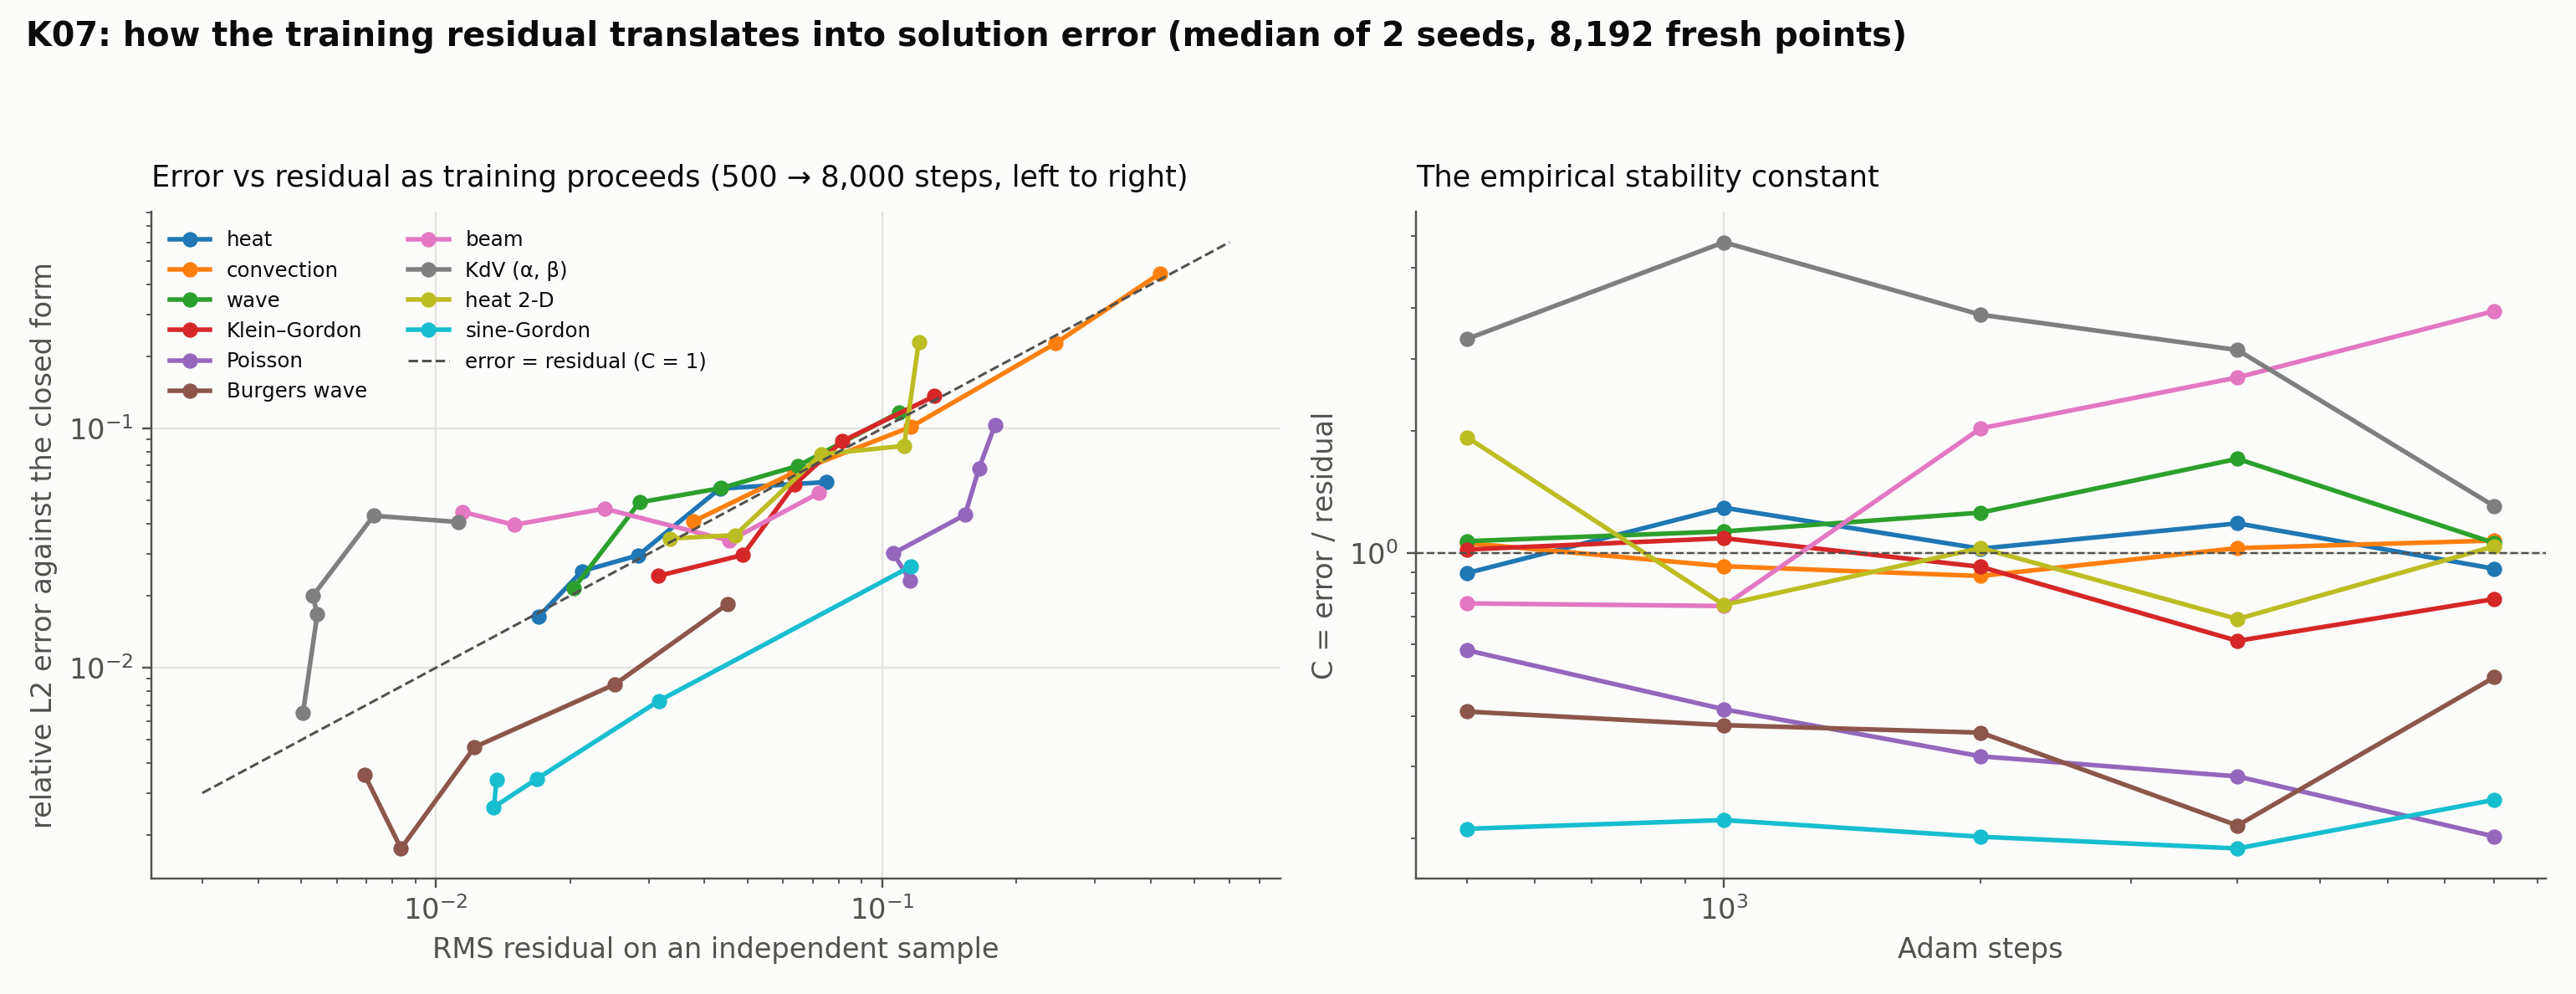

| equation | error at 8k steps | residual | boundary mismatch | C = error / residual | slope log err vs log res |
|---|---|---|---|---|---|
| heat | 0.016 | 1.7e-02 | 6.9e-03 | 0.92 | 0.87 |
| convection | 0.041 | 3.8e-02 | 4.5e-02 | 1.08 | 0.98 |
| wave | 0.021 | 2.0e-02 | 1.2e-02 | 1.06 | 0.88 |
| klein_gordon | 0.024 | 3.1e-02 | 1.1e-02 | 0.77 | 1.30 |
| poisson | 0.023 | 1.2e-01 | 1.6e-02 | 0.20 | 1.45 |
| burgers_travelling_wave | 0.004 | 6.9e-03 | 5.9e-03 | 0.50 | 1.18 |
| beam | 0.045 | 1.1e-02 | 1.2e-02 | 3.93 | 0.04 |
| kdv_two_parameter | 0.006 | 5.0e-03 | 3.2e-04 | 1.31 | 1.62 |
| heat_2d | 0.035 | 3.3e-02 | 1.2e-02 | 1.04 | 1.35 |
| sine_gordon | 0.003 | 1.4e-02 | 1.4e-02 | 0.25 | 1.05 |

**Conclusion (from `experiments/K07_stability_constants/README.md`)**


1. **For the linear evolution equations the constant is 1.** Heat, convection, wave, Klein–Gordon and heat in 2-D have $C$ between 0.8 and 1.3 at every budget and a slope near 1: the error falls in proportion to the residual, with a stability constant of order one, as the energy estimates for these well-posed problems say it should. For these equations the training residual on an independent sample *is* a usable error estimate.
2. **Scale and nonlinearity change the constant, not the law.** Poisson ($C \approx 0.2$–$0.6$) and sine-Gordon (0.2) have large residuals relative to the error because the residual carries the source term's scale ($2\pi^2$) or a large nonlinear term; the Burgers wave (0.4–0.5) and the KdV soliton (1.3–3.8) have constants away from 1 but slopes of 1.2–1.6, so the error still tracks the residual. The constant is a property of the equation, which is what the conditional-stability theory claims, and a per-equation calibration of $C$ from a closed-form case makes the residual an error estimate for cases without one.
3. **The beam violates the residual law because the residual is not the whole right-hand side.** Its error stalls at 4.5 % while the residual falls fourfold, and its boundary and initial mismatches stop falling at the level of the residual. The estimate $\text{error} \le C(\text{residual} + \text{boundary} + \text{initial} + \text{quadrature})$ holds; the estimate with the residual alone does not. The fourth-order operator makes the boundary conditions (two per end) the binding terms, which the loss weights of 10 do not enforce strongly enough.
4. **An independent sample is necessary.** The residual on the training points is the quantity the optimizer minimizes; the residual on fresh points includes the quadrature gap of the error estimate, and it is the one that correlates with the error. `stability_ratio` reports the four terms separately for this reason.

**Consequences for the backlog:**
- K33 (consistency vs convergence) has its first counterexample, the beam: the residual converges, the error does not, and the boundary terms explain it. Allen–Cahn and convection with large speeds are the cases to add.
- K38 (quadrature error): compare the training-point residual with the independent one as the point count grows, which this driver can do with one more column.
- The error estimate the package reports for a problem without a closed form should be $C \cdot (\text{residual} + \text{boundary} + \text{initial})$ with $C$ taken from the nearest calibrated equation and stated as such.


In [5]:
runs = load("K07_stability_constants")
figure("K07_stability_constants", "k07_stability_constants.png")
rows = []
for prob in ["heat", "convection", "wave", "klein_gordon", "poisson", "burgers_travelling_wave", "beam", "kdv_two_parameter", "heat_2d", "sine_gordon"]:
    sel = [r for r in runs if r["problem"] == prob]
    slope = np.polyfit(np.log([r["residual"] for r in sel]), np.log([r["error"] for r in sel]), 1)[0]
    last = [r for r in sel if r["steps"] == 8000]
    rows.append([prob, f"{np.median([r['error'] for r in last]):.3f}", f"{np.median([r['residual'] for r in last]):.1e}",
                 f"{np.median([r['boundary_error'] for r in last]):.1e}", f"{np.median([r['ratio'] for r in last]):.2f}", f"{slope:.2f}"])
table(["equation", "error at 8k steps", "residual", "boundary mismatch", "C = error / residual", "slope log err vs log res"], rows)
readme("K07_stability_constants")

## F06 / K10: are the intervals calibrated?

**Setup.** 30 synthetic data sets of the F01 cell; on each, an ensemble of 8 networks from different initializations, the Laplace posterior at member 0 (`pinnrl.uq.laplace_posterior`), the closed-form Fisher Gaussian at member 0, and the likelihood-ratio region of the *exact* misfit sampled by the swarm (`pinnrl.uq.sample_equivalence_region`). Coverage over the 30 data sets, mean width and CRPS.

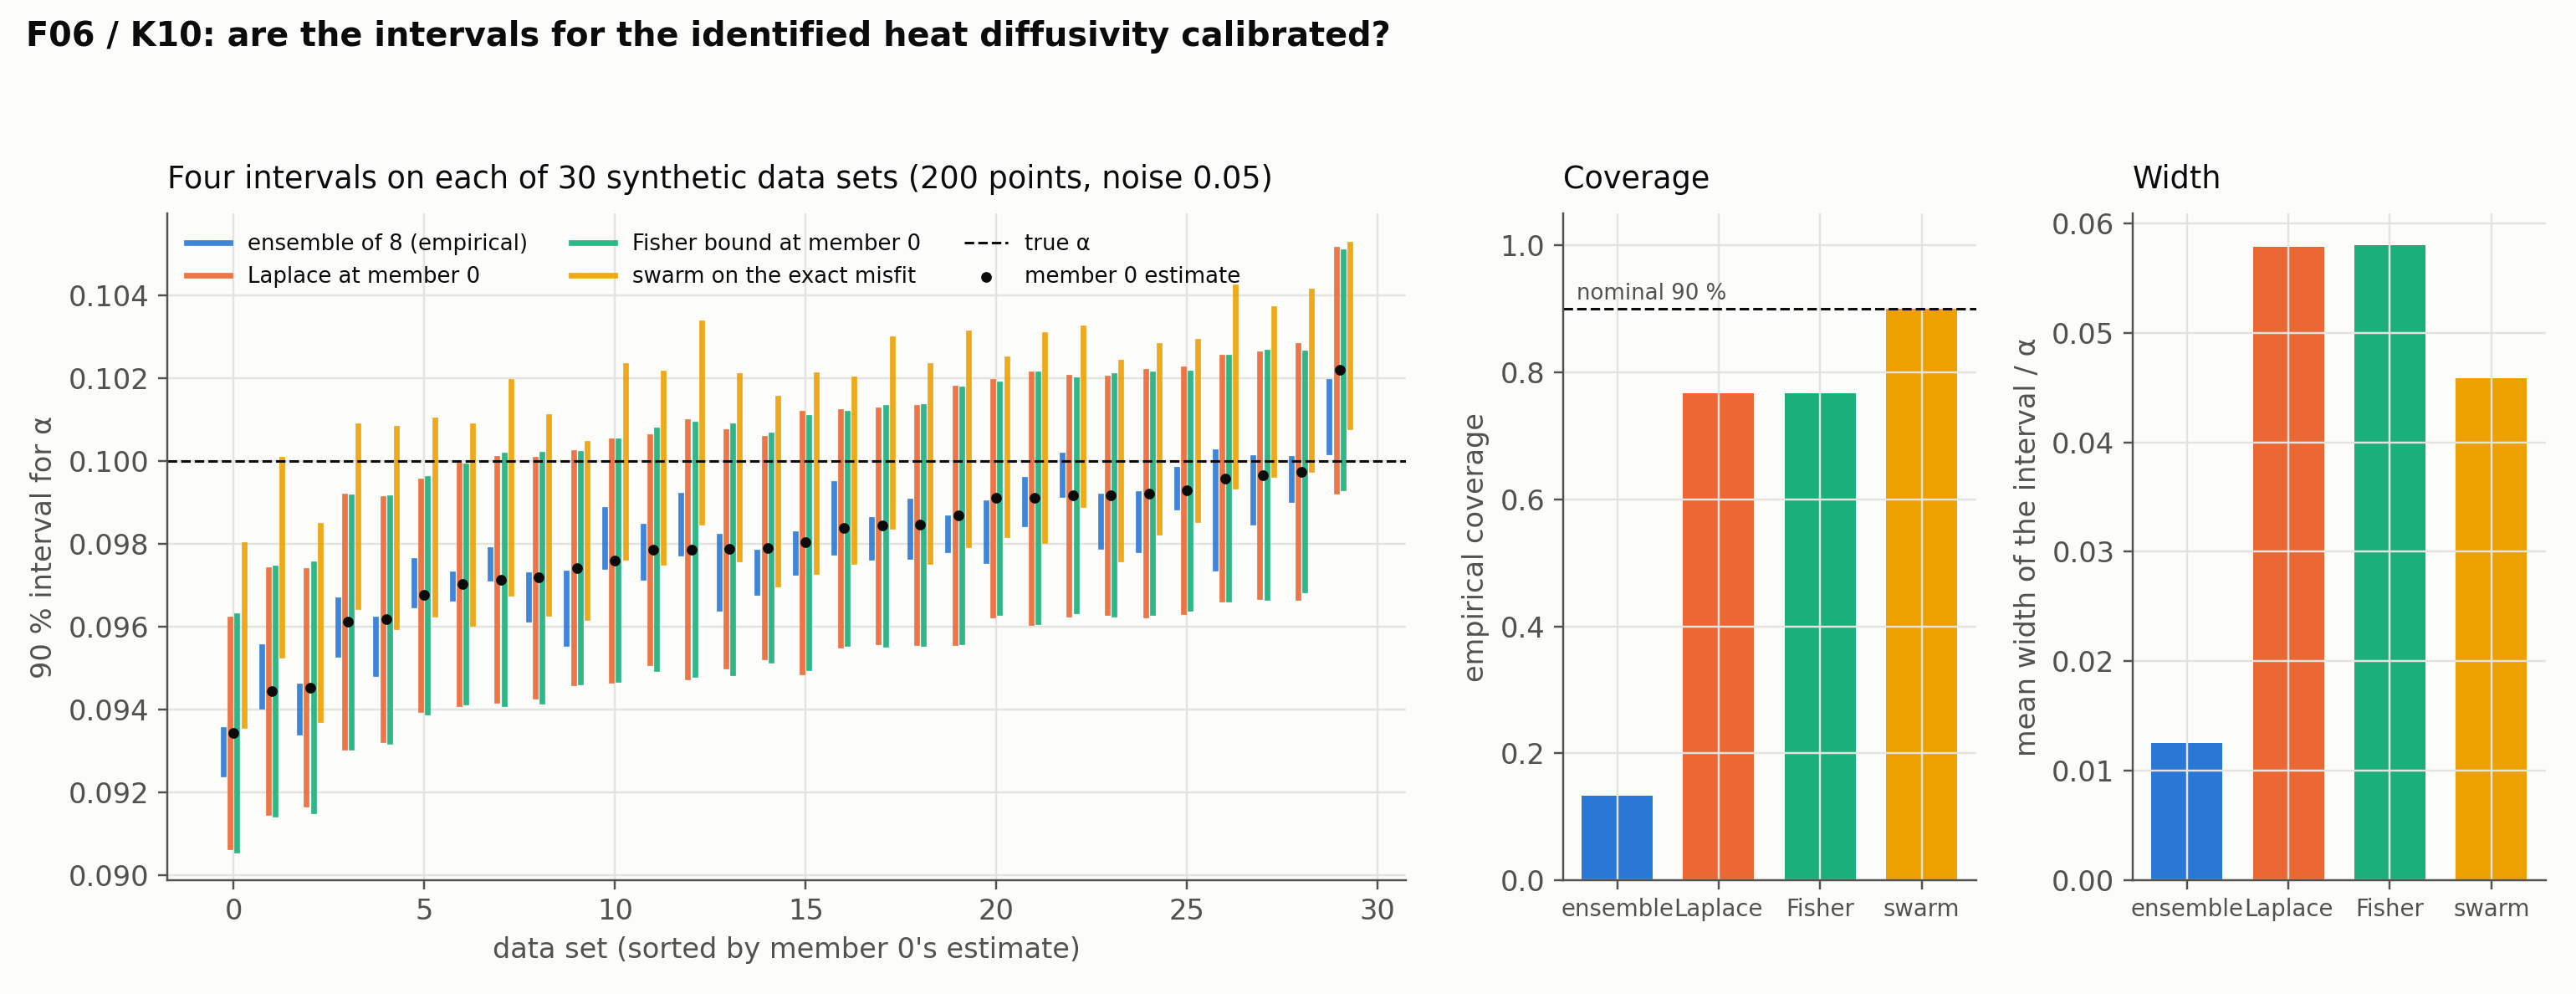

| interval | coverage (nominal 0.90) | mean width / α | mean CRPS |
|---|---|---|---|
| ensemble | 0.13 | 0.013 | 0.0021 |
| ensemble_gauss | 0.13 | 0.016 | – |
| laplace | 0.77 | 0.058 | 0.0016 |
| fisher | 0.77 | 0.058 | 0.0016 |
| swarm | 0.90 | 0.046 | – |

bias of member 0 across data sets: -0.021 α; spread across data sets: 0.0175 α; median Laplace std: 0.0175 α; median ensemble std: 0.0050 α


**Conclusion (from `experiments/F06_coverage/README.md`)**


1. **An ensemble over initializations is not an uncertainty estimate for the parameter.** Its members agree to 0.5 % while the estimate varies by 1.75 % from one noise draw to the next: the ensemble measures the surrogate's initialization noise, which is a quarter of the data noise, and covers the truth in 13 % of the data sets. Averaging members over the same data cannot see the noise of the data. Ensembles over *resampled data* (bootstrap) would; ensembles over seeds do not.
2. **The Laplace interval has exactly the right width and the wrong centre.** Its standard deviation, 0.00175, equals the spread of the estimate across data sets to three digits: the surrogate's Fisher information (K01) predicts the random error of the PINN estimate without error. Coverage is 77 % instead of 90 % because every interval is centred on an estimate that is 2.1 % low, the surrogate floor of F01; a Gaussian with the right width shifted by 1.2 standard deviations covers 69–77 % of the time, which is what is observed. The Laplace CRPS (0.0016) is the lowest of the methods.
3. **The swarm on the physics is calibrated, because it has no surrogate.** The likelihood-ratio region of the exact misfit covers the truth in 90 % of the data sets with a narrower interval than Laplace, since it is centred on the exact best fit rather than on the biased PINN estimate. It is the interval the data and the physics warrant; the PINN's shortfall from it is entirely the bias.
4. **Honest intervals for a PINN estimate therefore need two parts:** the Fisher width for the random error, which `pinnrl.uq.laplace_posterior` already provides, and a correction for the surrogate's systematic error, which no method internal to the model provides. The bias can be estimated where a closed form or a reference exists (as here), reduced by a better forward solve (D01/D02, the F02 data-weight lever), or bounded by the field error (K01's condition); the interval should state which.

**Consequences for the backlog:**
- K40 (ensemble size) is moot for parameter intervals over seeds; the ensemble question becomes a bootstrap over data (a new cell of F06).
- K41 (Laplace variants) can start from the fact that the θ-only Gauss–Newton Laplace is already exact for the random part; the question is whether the full-loss Hessian sees the bias.
- The documented interval for an identified parameter is "Laplace width, bias-corrected where a reference exists, otherwise widened by the field error", to be written into `pinnrl.uq` and the [Bayesian view](../../docs/theory/bayesian.md).


In [6]:
import csv
summary = json.loads((EXP / "F06_coverage" / "results" / "summary.json").read_text())
rows_f06 = list(csv.DictReader(open(EXP / "F06_coverage" / "results" / "intervals.csv")))
figure("F06_coverage", "f06_coverage.png")
table(["interval", "coverage (nominal 0.90)", "mean width / α", "mean CRPS"],
      [[k, f"{summary[k]['coverage']:.2f}", f"{summary[k]['mean_width'] / 0.1:.3f}", f"{summary[k]['crps']:.4f}" if "crps" in summary[k] else "–"]
       for k in ["ensemble", "ensemble_gauss", "laplace", "fisher", "swarm"]])
print(f"bias of member 0 across data sets: {summary['bias_member0'] / 0.1:+.3f} α; spread across data sets: {summary['spread_member0_across_datasets'] / 0.1:.4f} α; "
      f"median Laplace std: {np.median([float(r['laplace_std']) for r in rows_f06]) / 0.1:.4f} α; median ensemble std: {summary['mean_ensemble_std'] / 0.1:.4f} α")
readme("F06_coverage")

**A view the README does not have.** The Laplace standard deviation on each data set against the spread of the estimate across data sets: if the surrogate's Fisher information is right, every point sits at the horizontal line.

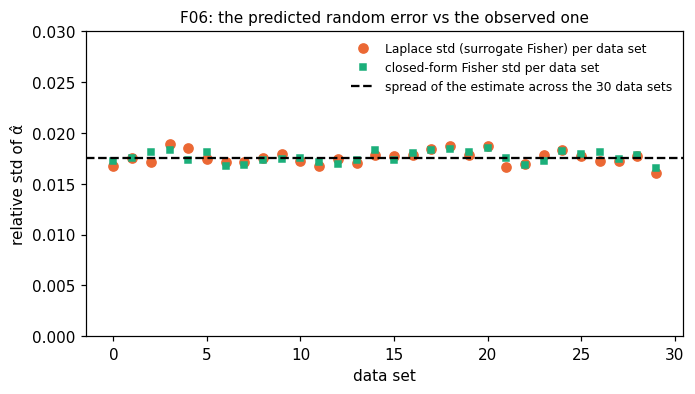

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
lap = np.array([float(r["laplace_std"]) for r in rows_f06]) / 0.1
fis = np.array([float(r["fisher_std"]) for r in rows_f06]) / 0.1
ax.plot(lap, "o", color="#eb6834", label="Laplace std (surrogate Fisher) per data set")
ax.plot(fis, "s", color="#1baf7a", markersize=4, label="closed-form Fisher std per data set")
ax.axhline(summary["spread_member0_across_datasets"] / 0.1, color="black", linestyle="--", label="spread of the estimate across the 30 data sets")
ax.set_xlabel("data set"); ax.set_ylabel("relative std of α̂"); ax.set_ylim(0, 0.03)
ax.set_title("F06: the predicted random error vs the observed one", fontsize=10); ax.legend(frameon=False, fontsize=8)
plt.show()

## K39: the data weight from the noise model

**Setup.** Three data weights for the heat identification at noise 0.01, 0.05 and 0.1: the fixed 10, a fixed 100, and the likelihood weight $(N_d/\sigma^2)/(N_r/\sigma_r^2)$ with a model-error scale $\sigma_r = 0.1$, which gives 20, 0.8 and 0.2. If the residual were Gaussian model error, the third would be the right one.

In [8]:
runs = load("K39_likelihood_weighting")
rows = []
for noise in sorted({r["noise"] for r in runs}):
    for scheme in ["fixed_10", "fixed_100", "likelihood"]:
        sel = [r for r in runs if r["noise"] == noise and r["scheme"] == scheme]
        a = np.array([r["alpha_hat"] for r in sel])
        rows.append([noise, scheme, f"{sel[0]['data_weight']:.2g}", med_iqr([r["rel_error"] for r in sel]), f"{a.std() / 0.1:.3f}", f"{(a.mean() - 0.1) / 0.1:+.3f}",
                     f"{np.median([r['residual_loss'] for r in sel]):.1e}", f"{np.median([r['data_loss'] for r in sel]):.1e}"])
table(["noise σ", "scheme", "data weight", "rel. error of α, median [IQR]", "spread", "bias", "residual loss", "data loss"], rows)
readme("K39_likelihood_weighting")

| noise σ | scheme | data weight | rel. error of α, median [IQR] | spread | bias | residual loss | data loss |
|---|---|---|---|---|---|---|---|
| 0.01 | fixed_10 | 10 | 0.019 [0.015, 0.020] | 0.005 | -0.019 | 8.1e-04 | 2.1e-04 |
| 0.01 | fixed_100 | 1e+02 | 0.036 [0.030, 0.041] | 0.006 | -0.036 | 2.7e-03 | 2.1e-04 |
| 0.01 | likelihood | 20 | 0.022 [0.020, 0.025] | 0.005 | -0.022 | 1.2e-03 | 2.2e-04 |
| 0.05 | fixed_10 | 10 | 0.021 [0.013, 0.032] | 0.019 | -0.027 | 8.6e-04 | 2.7e-03 |
| 0.05 | fixed_100 | 1e+02 | 0.037 [0.032, 0.055] | 0.030 | -0.047 | 4.4e-03 | 2.5e-03 |
| 0.05 | likelihood | 0.8 | 0.064 [0.052, 0.089] | 0.018 | -0.070 | 6.0e-04 | 2.8e-03 |
| 0.1 | fixed_10 | 10 | 0.024 [0.009, 0.046] | 0.037 | -0.038 | 1.1e-03 | 1.0e-02 |
| 0.1 | fixed_100 | 1e+02 | 0.048 [0.034, 0.092] | 0.066 | -0.072 | 1.3e-02 | 9.7e-03 |
| 0.1 | likelihood | 0.2 | 0.202 [0.183, 0.232] | 0.029 | -0.206 | 5.5e-04 | 1.2e-02 |

**Conclusion (from `experiments/K39_likelihood_weighting/README.md`)**


1. **The weight from the noise model is the worst of the three.** With the residual treated as Gaussian model error of scale $\sigma_r = 0.1$, the data weight falls to 0.8 at $\sigma = 0.05$ and 0.2 at $\sigma = 0.1$, and the bias of $\hat\alpha$ grows to −7 % and −21 %: a weak data term leaves the estimate to the physics term, whose minimum is the surrogate's floor (F01), not the truth. The Gaussian likelihood is the right accounting for *noise*, but the residual of a trained PINN is not noise. It is a systematic approximation error, correlated across the domain, with a minimum displaced from the true parameters; weighting it as if it were independent Gaussian error overstates how much the physics term should be trusted.
2. **Too much data weight hurts the other way.** At a fixed 100 the data term chases the noise: the residual loss rises 3–12×, the field error doubles at $\sigma = 0.1$, and the bias doubles. The data term then reports the noise draw more than the physics.
3. **The tuned 10 sits at the balance, and the balance is set by the surrogate, not by the noise.** The right weight is the one at which the data pull on $\alpha$ just overcomes the surrogate's systematic preference without fitting noise. In F02, where the floor was 20 %, a weight of 100 was the improvement; here, where the floor is 2 %, 10 is. The weight should therefore be set from the *surrogate's* error model (its floor relative to the noise), which the likelihood recipe does not know.
4. **For calibration the recipe still matters.** K10 reads the Laplace width off the Fisher information with the noise $\sigma$, which is independent of the loss weight; what the weight changes is the bias, and that is what the F06 coverage shortfall measures.

**Consequences for the backlog:**
- The Bayesian weighting of the [theory](../../docs/theory/bayesian.md) needs a model-error term for the surrogate (a residual scale learned from the data, or an iterative reweighting), which is the honest version of K39 and belongs to K41/K43.
- The data weight stays a documented choice in `pinnrl`, with 10 as the default and the F02 rule of thumb: raise it when the field error is large compared with the noise.


## K46: the region of equivalence sampled by a swarm

**Setup.** On three closed-form forward maps (heat α; the two-parameter KdV soliton; the saturation model of Pallero et al.), a cloud particle swarm samples the likelihood-ratio region of a noisy data set and the accepted set is compared with the 90 % Fisher ellipse at the best fit. The figure below is re-rendered live (the swarm takes a second).

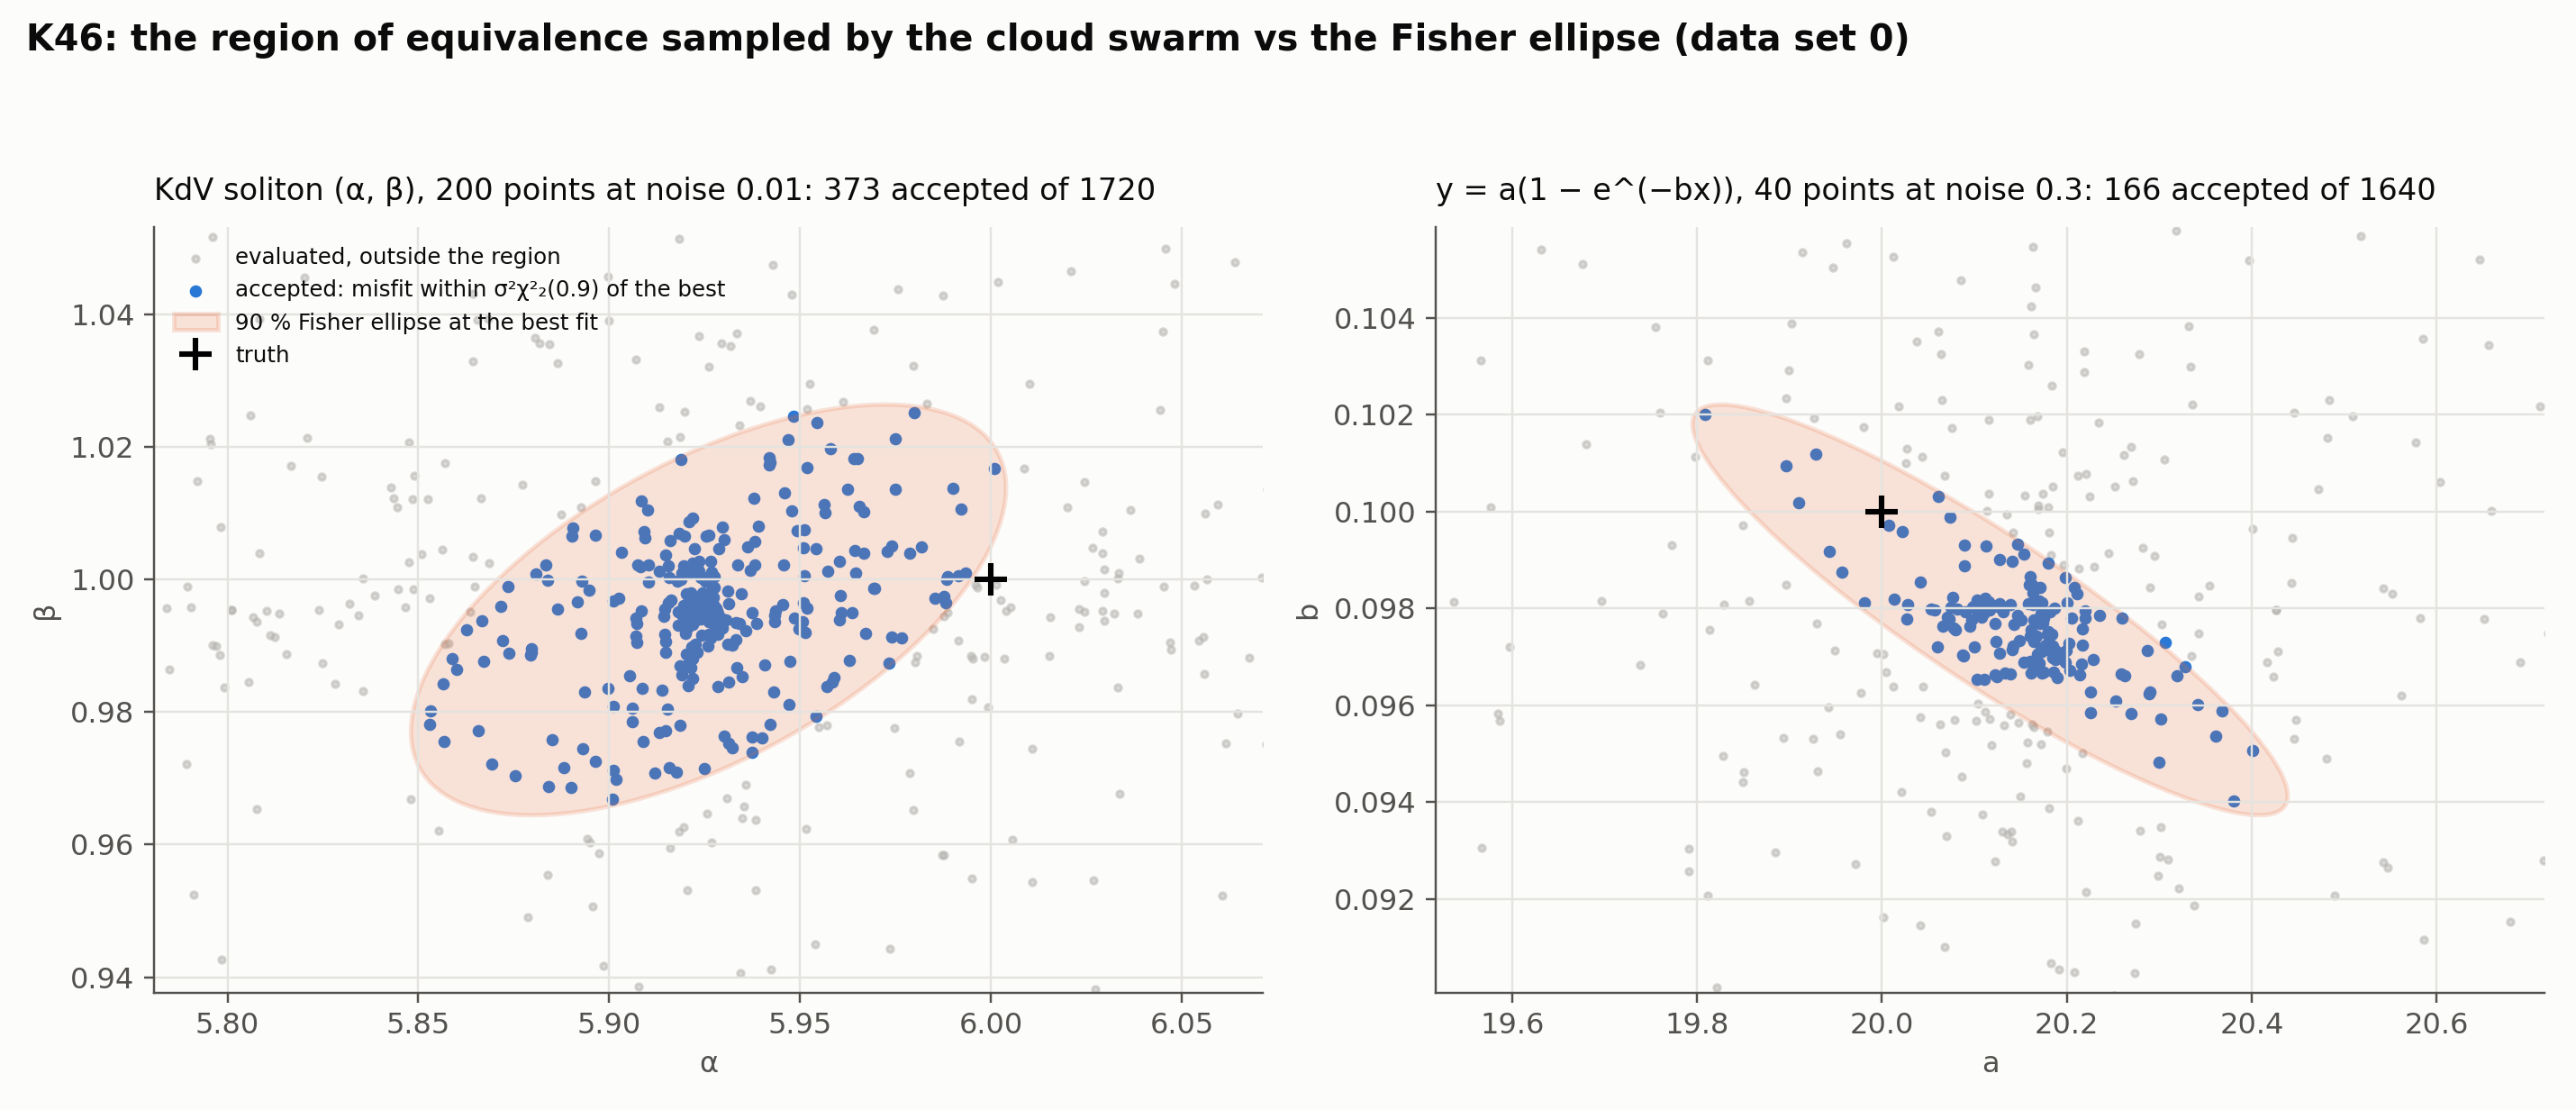

| problem | accepted / evaluated | truth in 90 % interval | samples inside the Fisher ellipse | swarm width / ellipse width | correlation: samples / ellipse |
|---|---|---|---|---|---|
| heat | 240 / 945 | 8 / 10 | 1.00 | 0.79 | – |
| kdv_two_parameter | 250 / 1440 | 4 / 10 | 1.00 | 0.75, 0.75 | +0.35 / +0.61 |
| saturation_a_b | 164 / 1340 | 5 / 10 | 0.99 | 0.58, 0.57 | -0.68 / -0.90 |

**Conclusion (from `experiments/K46_swarm_equivalence/README.md`)**


1. **At these noise levels the regions are ellipses.** On all three problems 94–100 % of the accepted samples lie inside the 90 % Fisher ellipse centred on the best fit, including the saturation model that is banana-shaped at larger noise: the likelihood-ratio region of a mildly nonlinear problem with good data is the linearized one. The swarm confirms the ellipse rather than correcting it here; the cases where it would correct it are the F02 displaced optimum and noisier data, and those need the parametric surrogate (K45) to be affordable.
2. **The swarm under-samples the edges of the region.** The swarm's 90 % interval is 0.57–0.79 of the ellipse's width and its correlation is weaker than the ellipse's (+0.35 vs +0.61, −0.68 vs −0.90): the sample is dense near the best fit and thin near the acceptance boundary, because the particles converge and the run stops on collapse (dispersion 0.02 after 25–40 iterations). The retained samples are an approximation of the region, as the papers say, and not a uniform or a posterior sample of it; a percentile read from them is biased inward. This is why the truth falls in the swarm interval only 4–8 times in 10 instead of 9.
3. **Two fixes, both cheap, both to measure (K47).** Keep the swarm exploring once it has found the region (raise the time step or add repulsion, as the papers do, rather than stopping on collapse), and weight the retained samples by $\exp(-\text{misfit}/2\sigma^2)$ so that the dense centre does not dominate the percentiles. Until then the swarm interval is reported together with the ellipse, and the wider of the two is the honest one.

**Consequences for the backlog:**
- K47 (is the swarm sample a posterior sample?) is the next step, with the exploration-after-convergence and the likelihood weighting as its two arms, judged by coverage over data sets as in F06.
- K45 (parametric surrogate) is what makes the swarm applicable to the PINN's own misfit, where the region is known to be displaced (F02) and the ellipse is wrong.


In [9]:
runs = load("K46_swarm_equivalence")
figure("K46_swarm_equivalence", "k46_swarm_equivalence.png")
rows = []
for prob in ["heat", "kdv_two_parameter", "saturation_a_b"]:
    sel = [r for r in runs if r["problem"] == prob]
    rows.append([prob, f"{np.median([r['n_accepted'] for r in sel]):.0f} / {np.median([r['n_evaluated'] for r in sel]):.0f}",
                 f"{sum(r['truth_in_interval'] for r in sel)} / {len(sel)}", f"{np.median([r['fraction_inside_fisher_90'] for r in sel]):.2f}",
                 ", ".join(f"{v:.2f}" for v in np.median([r["width_ratio_swarm_over_fisher"] for r in sel], axis=0)),
                 f"{np.median([r.get('sample_correlation', np.nan) for r in sel]):+.2f} / {np.median([r.get('fisher_correlation', np.nan) for r in sel]):+.2f}" if "sample_correlation" in sel[0] else "–"])
table(["problem", "accepted / evaluated", "truth in 90 % interval", "samples inside the Fisher ellipse", "swarm width / ellipse width", "correlation: samples / ellipse"], rows)
readme("K46_swarm_equivalence")

## What to take from these six experiments

- **The linear theory predicts the PINN's response to data disturbances** to within 20 % for bias and delay, which makes $F^{-1}J^\top\Sigma^{-1}$ a design tool for sensor requirements; a bias of the noise level moves the estimate by 18 % and nothing in the physics flags it (K05).
- **A trained surrogate has a resolution**, its field error, below which it cannot register a change of the problem; above it, it respects the equation's stability (K06). For linear evolution equations the residual on an independent sample is an error estimate with $C \approx 1$; for the beam the boundary terms, not the residual, set the error (K07).
- **The honest interval for a PINN estimate has two parts:** the Fisher width, which the Laplace posterior gets exactly right, and a correction for the surrogate's systematic error, which no internal method provides and which costs 13 points of coverage here (F06). Ensembles over initializations measure the wrong noise (13 % coverage).
- **The data weight is set by the surrogate's floor, not by the noise model** (K39); and **the swarm confirms the Fisher ellipse where the problem is nearly linear** and needs exploration after convergence to sample the region's edges (K46).